In [1]:
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import DataLoader, Subset
from torchvision import models, transforms, datasets
from sklearn.model_selection import train_test_split
from sklearn.metrics import f1_score, accuracy_score
import numpy as np
import random
import time
import json
import copy
import pandas as pd

In [2]:
# ==========================================
# 0. Set Random Seed (Reproduksibilitas)
# ==========================================
def set_seed(seed=42):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.deterministic = True

set_seed(42)

In [3]:
# Deteksi otomatis device: MPS (Apple Silicon GPU), CUDA, atau CPU
if torch.backends.mps.is_available():
    device = torch.device("mps")
    print("Menggunakan Device: Apple Silicon GPU (MPS)")
elif torch.cuda.is_available():
    device = torch.device("cuda")
    print("Menggunakan Device: CUDA GPU")
else:
    device = torch.device("cpu")
    print("Menggunakan Device: CPU")

Menggunakan Device: Apple Silicon GPU (MPS)


In [4]:
# ==========================================
# 1. Persiapan Dataset Oxford-IIIT Pet (10 Kelas)
# ==========================================
# Pilih 5 ras kucing dan 5 ras anjing
TARGET_CLASSES = [
    'Abyssinian', 'Bengal', 'Birman', 'Bombay', 'Persian',  # Cats
    'American Bulldog', 'American Pit Bull Terrier', 'Basset Hound', 'Beagle', 'Boxer' # Dogs
]

# Unduh dataset mentah untuk mengekstrak label
raw_dataset = datasets.OxfordIIITPet(root='./data', split='trainval', download=True)
class_to_idx = {cls_name: i for i, cls_name in enumerate(raw_dataset.classes)}
target_indices = [class_to_idx[cls] for cls in TARGET_CLASSES]

# Filter sampel yang termasuk dalam 10 kelas target
filtered_indices = [i for i, label in enumerate(raw_dataset._labels) if label in target_indices]
filtered_labels = [raw_dataset._labels[i] for i in filtered_indices]

# Mapping ulang label ke rentang 0-9
label_map = {old_idx: new_idx for new_idx, old_idx in enumerate(target_indices)}
mapped_labels = [label_map[lbl] for lbl in filtered_labels]

# Stratified Split: 70% Train, 15% Val, 15% Test
train_idx, temp_idx, train_lbl, temp_lbl = train_test_split(
    filtered_indices, mapped_labels, test_size=0.30, stratify=mapped_labels, random_state=42
)
val_idx, test_idx, val_lbl, test_lbl = train_test_split(
    temp_idx, temp_lbl, test_size=0.50, stratify=temp_lbl, random_state=42
)

# Custom Dataset Wrapper untuk Mapping Label & Transformasi terpisah
class MappedPetDataset(torch.utils.data.Dataset):
    def __init__(self, base_dataset, indices, label_map, transform=None):
        self.base_dataset = base_dataset
        self.indices = indices
        self.label_map = label_map
        self.transform = transform

    def __len__(self):
        return len(self.indices)

    def __getitem__(self, idx):
        orig_idx = self.indices[idx]
        img, label = self.base_dataset[orig_idx]
        if self.transform:
            img = self.transform(img)
        return img, self.label_map[label]

# Transformasi Standard ImageNet
weights = models.ResNet18_Weights.IMAGENET1K_V1
mean_std = (weights.transforms().mean, weights.transforms().std)

train_transforms_aug = transforms.Compose([
    transforms.Resize(256),
    transforms.RandomResizedCrop(224, scale=(0.8, 1.0)),
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.RandomRotation(degrees=15),
    transforms.ColorJitter(brightness=0.2, contrast=0.2),
    transforms.ToTensor(),
    transforms.Normalize(mean=mean_std[0], std=mean_std[1])
])

eval_transforms = transforms.Compose([
    transforms.Resize(256),
    transforms.CenterCrop(224),
    transforms.ToTensor(),
    transforms.Normalize(mean=mean_std[0], std=mean_std[1])
])

# DataLoader Helper
def get_dataloaders(use_aug=True):
    t_trans = train_transforms_aug if use_aug else eval_transforms
    
    train_ds = MappedPetDataset(raw_dataset, train_idx, label_map, transform=t_trans)
    val_ds   = MappedPetDataset(raw_dataset, val_idx, label_map, transform=eval_transforms)
    test_ds  = MappedPetDataset(raw_dataset, test_idx, label_map, transform=eval_transforms)

    train_loader = DataLoader(train_ds, batch_size=32, shuffle=True, num_workers=0)
    val_loader   = DataLoader(val_ds, batch_size=32, shuffle=False, num_workers=0)
    test_loader  = DataLoader(test_ds, batch_size=32, shuffle=False, num_workers=0)
    
    return train_loader, val_loader, test_loader


In [5]:
# ==========================================
# 2. Engine Pelatihan dan Evaluasi
# ==========================================
def train_and_evaluate(model, optimizer, train_loader, val_loader, test_loader, epochs=20, patience=4):
    criterion = nn.CrossEntropyLoss()
    best_val_loss = float('inf')
    patience_counter = 0
    best_model_weights = None
    best_epoch = 0
    history = {"train_loss": [], "val_loss": [], "val_acc": []}
    
    start_time = time.time()
    
    for epoch in range(epochs):
        model.train()
        train_loss = 0.0
        for inputs, labels in train_loader:
            inputs, labels = inputs.to(device), labels.to(device)
            optimizer.zero_grad()
            outputs = model(inputs)
            loss = criterion(outputs, labels)
            loss.backward()
            optimizer.step()
            train_loss += loss.item() * inputs.size(0)
            
        train_loss /= len(train_loader.dataset)
        
        # Validation Phase
        model.eval()
        val_loss, correct = 0.0, 0
        with torch.no_grad():
            for inputs, labels in val_loader:
                inputs, labels = inputs.to(device), labels.to(device)
                outputs = model(inputs)
                loss = criterion(outputs, labels)
                val_loss += loss.item() * inputs.size(0)
                preds = outputs.argmax(dim=1)
                correct += (preds == labels).sum().item()
                
        val_loss /= len(val_loader.dataset)
        val_acc = correct / len(val_loader.dataset)
        
        # Catat history per epoch
        history["train_loss"].append(train_loss)
        history["val_loss"].append(val_loss)
        history["val_acc"].append(val_acc)
        
        # Early Stopping Check
        if val_loss < best_val_loss:
            best_val_loss = val_loss
            patience_counter = 0
            best_epoch = epoch + 1
            best_model_weights = copy.deepcopy(model.state_dict())
        else:
            patience_counter += 1
            if patience_counter >= patience:
                break

    total_time = time.time() - start_time
    
    # Evaluation on Test Set using Best Weights
    model.load_state_dict(best_model_weights)
    model.eval()
    all_preds, all_labels = [], []
    with torch.no_grad():
        for inputs, labels in test_loader:
            inputs = inputs.to(device)
            outputs = model(inputs)
            preds = outputs.argmax(dim=1)
            all_preds.extend(preds.cpu().numpy())
            all_labels.extend(labels.numpy())
            
    test_acc = accuracy_score(all_labels, all_preds)
    test_f1 = f1_score(all_labels, all_preds, average='macro')
    
    return {
        "converged_epoch": best_epoch,
        "total_time_sec": round(total_time, 2),
        "val_acc": round(val_acc, 4),
        "test_acc": round(test_acc, 4),
        "test_f1_macro": round(test_f1, 4)
    }, history


In [6]:
# ==========================================
# 3. Eksekusi Matriks Eksperimen (B1 - B5)
# ==========================================
results = []

# --- B1: Baseline from Scratch ---
model_b1 = models.resnet18(weights=None)
model_b1.fc = nn.Linear(512, 10)
model_b1.to(device)
opt_b1 = optim.AdamW(model_b1.parameters(), lr=1e-3, weight_decay=1e-2)
train_ld, val_ld, test_ld = get_dataloaders(use_aug=True)

res_b1, hist_b1 = train_and_evaluate(model_b1, opt_b1, train_ld, val_ld, test_ld)
res_b1.update({"code": "B1", "condition": "Baseline From Scratch", "trainable_params": sum(p.numel() for p in model_b1.parameters() if p.requires_grad), "lr": "1e-3"})
results.append(res_b1)

# --- B2: Feature Extraction ---
model_b2 = models.resnet18(weights=models.ResNet18_Weights.IMAGENET1K_V1)
for param in model_b2.parameters():
    param.requires_grad = False
model_b2.fc = nn.Linear(512, 10)
model_b2.to(device)
opt_b2 = optim.AdamW(model_b2.fc.parameters(), lr=1e-3, weight_decay=1e-2)

res_b2, hist_b2 = train_and_evaluate(model_b2, opt_b2, train_ld, val_ld, test_ld)
res_b2.update({"code": "B2", "condition": "Feature Extraction", "trainable_params": sum(p.numel() for p in model_b2.parameters() if p.requires_grad), "lr": "1e-3 (fc)"})
results.append(res_b2)

# --- B3: Progressive Fine-Tuning ---
model_b3 = models.resnet18(weights=models.ResNet18_Weights.IMAGENET1K_V1)
for param in model_b3.parameters():
    param.requires_grad = False
for param in model_b3.layer4.parameters():
    param.requires_grad = True
model_b3.fc = nn.Linear(512, 10)
model_b3.to(device)
opt_b3 = optim.AdamW([
    {"params": model_b3.layer4.parameters(), "lr": 1e-4},
    {"params": model_b3.fc.parameters(), "lr": 1e-3}
], weight_decay=1e-2)

res_b3, hist_b3 = train_and_evaluate(model_b3, opt_b3, train_ld, val_ld, test_ld)
res_b3.update({"code": "B3", "condition": "Progressive Fine-Tuning", "trainable_params": sum(p.numel() for p in model_b3.parameters() if p.requires_grad), "lr": "1e-4 (l4), 1e-3 (fc)"})
results.append(res_b3)

# --- B4: Uji Kontrol Data Augmentation (Tanpa Augmentasi pada B3) ---
train_ld_noaug, val_ld, test_ld = get_dataloaders(use_aug=False)
model_b4 = models.resnet18(weights=models.ResNet18_Weights.IMAGENET1K_V1)
for param in model_b4.parameters():
    param.requires_grad = False
for param in model_b4.layer4.parameters():
    param.requires_grad = True
model_b4.fc = nn.Linear(512, 10)
model_b4.to(device)
opt_b4 = optim.AdamW([
    {"params": model_b4.layer4.parameters(), "lr": 1e-4},
    {"params": model_b4.fc.parameters(), "lr": 1e-3}
], weight_decay=1e-2)

res_b4, hist_b4 = train_and_evaluate(model_b4, opt_b4, train_ld_noaug, val_ld, test_ld)
res_b4.update({"code": "B4", "condition": "Fine-Tuning (Tanpa Augmentasi)", "trainable_params": sum(p.numel() for p in model_b4.parameters() if p.requires_grad), "lr": "1e-4 (l4), 1e-3 (fc)"})
results.append(res_b4)

# --- B5: Arsitektur Pembanding (EfficientNet-B0) ---
model_b5 = models.efficientnet_b0(weights=models.EfficientNet_B0_Weights.IMAGENET1K_V1)
for param in model_b5.parameters():
    param.requires_grad = False
# Unfreeze blok terakhir (features[7]) & ganti classifier
for param in model_b5.features[7].parameters():
    param.requires_grad = True
model_b5.classifier[1] = nn.Linear(1280, 10)
model_b5.to(device)
opt_b5 = optim.AdamW([
    {"params": model_b5.features[7].parameters(), "lr": 1e-4},
    {"params": model_b5.classifier.parameters(), "lr": 1e-3}
], weight_decay=1e-2)

res_b5, hist_b5 = train_and_evaluate(model_b5, opt_b5, train_ld, val_ld, test_ld)
res_b5.update({"code": "B5", "condition": "EfficientNet-B0 Fine-Tuning", "trainable_params": sum(p.numel() for p in model_b5.parameters() if p.requires_grad), "lr": "1e-4 (f7), 1e-3 (cls)"})
results.append(res_b5)

In [7]:
# ==========================================
# 4. Simpan Log Mentah (.csv dan .json)
# ==========================================
df_results = pd.DataFrame(results)
df_results.to_csv("experiment_log.csv", index=False)
with open("experiment_log.json", "w") as f:
    json.dump(results, f, indent=4)

print("Eksperimen selesai. Log berhasil disimpan ke experiment_log.csv dan experiment_log.json.")

Eksperimen selesai. Log berhasil disimpan ke experiment_log.csv dan experiment_log.json.


In [8]:
import matplotlib.pyplot as plt
import numpy as np

def visualize_feature_maps(model_b2, model_b3, input_tensor, original_img):
    """
    Ekstraksi dan visualisasi peta aktivasi layer4
    antara B2 (Feature Extraction) dan B3 (Fine-Tuned).
    """
    activation_b2 = {}
    activation_b3 = {}

    # Hook untuk menangkap aktivasi keluaran layer4
    def get_activation(storage_dict):
        def hook(model, input, output):
            storage_dict['layer4'] = output.detach()
        return hook

    model_b2.layer4.register_forward_hook(get_activation(activation_b2))
    model_b3.layer4.register_forward_hook(get_activation(activation_b3))

    # Forward pass
    model_b2.eval()
    model_b3.eval()
    with torch.no_grad():
        _ = model_b2(input_tensor)
        _ = model_b3(input_tensor)

    # Ambil rerata aktivasi melintasi seluruh channel (feature map)
    map_b2 = activation_b2['layer4'][0].mean(dim=0).cpu().numpy()
    map_b3 = activation_b3['layer4'][0].mean(dim=0).cpu().numpy()

    # Plot Perbandingan
    fig, axes = plt.subplots(1, 3, figsize=(15, 5))

    axes[0].imshow(original_img)
    axes[0].set_title("Citra Input Asli")
    axes[0].axis('off')

    axes[1].imshow(map_b2, cmap='viridis')
    axes[1].set_title("Feature Map B2 (Sebelum Fine-Tuning)")
    axes[1].axis('off')

    axes[2].imshow(map_b3, cmap='viridis')
    axes[2].set_title("Feature Map B3 (Sesudah Fine-Tuning)")
    axes[2].axis('off')

    plt.tight_layout()
    plt.savefig('feature_map_comparison_c5.png', dpi=300)
    plt.show()

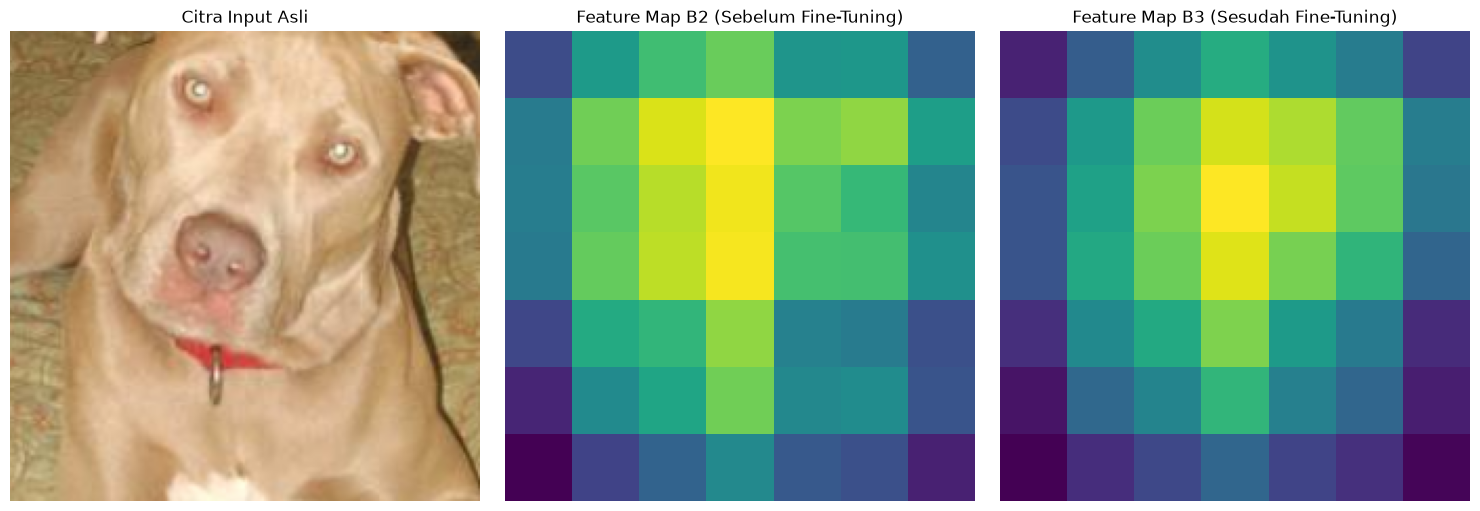

In [9]:
# =========================================
# Eksekusi Visualisasi Feature Map (C5)
# =========================================

# Inisialisasi data loader
train_loader, val_loader, test_loader = get_dataloaders(use_aug=False)

# Ambil 1 sampel citra dari test_loader
sample_img_tensor, sample_label = next(iter(test_loader))

# Tambahkan dimensi batch (1, C, H, W) dan pindahkan ke device
input_tensor = sample_img_tensor[0].unsqueeze(0).to(device)

# Rekonstruksi citra asli untuk visualisasi (denormalisasi)
def denormalize(tensor):
    mean = np.array([0.485, 0.456, 0.406])
    std = np.array([0.229, 0.224, 0.225])
    img = tensor.cpu().numpy().transpose((1, 2, 0))
    img = std * img + mean
    return np.clip(img, 0, 1)

original_img = denormalize(sample_img_tensor[0])

# Panggil fungsi visualisasi C5
visualize_feature_maps(model_b2, model_b3, input_tensor, original_img)

In [10]:
def plot_training_curves(history_b1, history_b2, history_b3):
    histories = [history_b1, history_b2, history_b3]
    titles = ['B1 (Scratch)', 'B2 (Feature Ext)', 'B3 (Fine-Tuning)']

    fig, axes = plt.subplots(1, 3, figsize=(18, 5), sharey=True)

    for ax, hist, title in zip(axes, histories, titles):
        epochs_range = range(1, len(hist['train_loss']) + 1)
        ax.plot(epochs_range, hist['train_loss'], label='Train Loss', linestyle='--', marker='o', markersize=3)
        ax.plot(epochs_range, hist['val_loss'], label='Val Loss', linestyle='-', marker='s', markersize=3)
        ax.set_title(f'Kurva Loss {title}')
        ax.set_xlabel('Epoch')
        ax.set_ylabel('Loss')
        ax.legend()
        ax.grid(True)

    plt.tight_layout()
    plt.savefig('learning_curves_c1.png', dpi=300)
    plt.show()

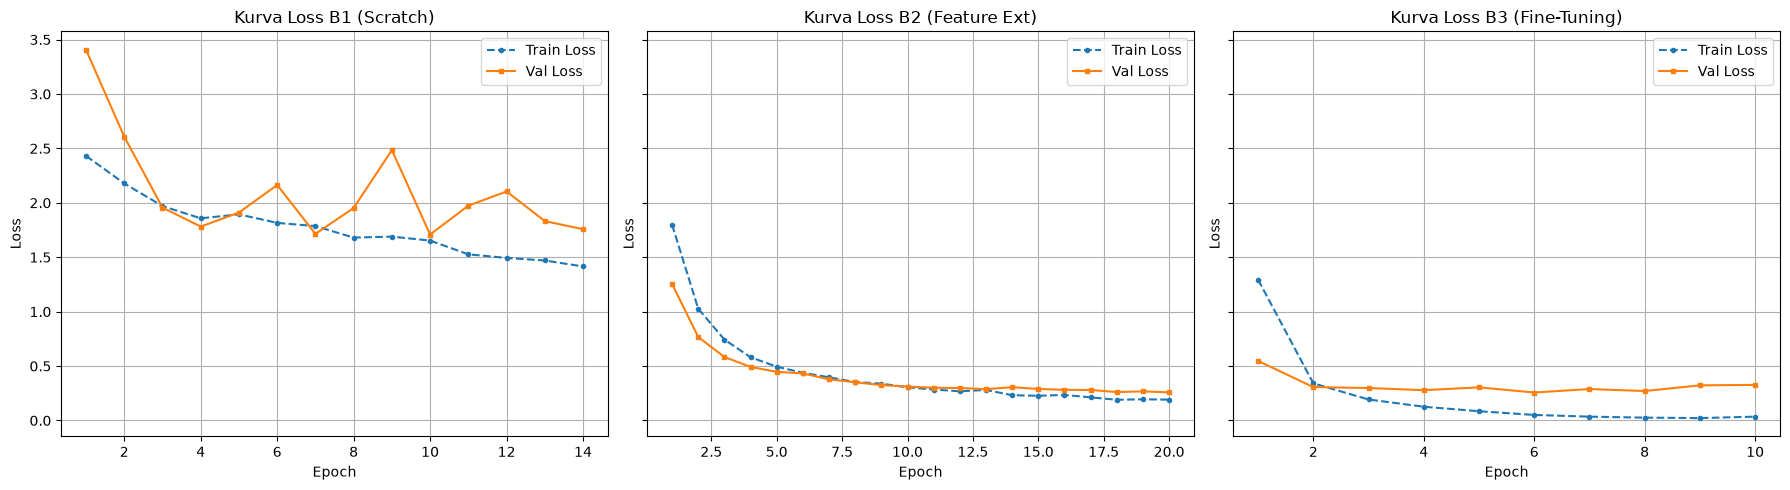

In [11]:
plot_training_curves(hist_b1, hist_b2, hist_b3)